# F1 lap-time prediction across the 2026 regulation change
## Notebook 01 — data loading, validation, pre-processing and first EDA

**Question:** does a lap-time model trained on 2022–2025 still work on 2026 cars, and how many 2026 races does it need to recover?

**Data source:** [TracingInsights](https://github.com/TracingInsights) season repositories, which publish FastF1-derived race lap tables (lap time, tyre, stint, track status, pit flags, and weather joined per lap) for every race.

The download, cleaning funnel, target and feature encoding live in the `f1lap` package under `src/`; this notebook orchestrates them and does the EDA.

In [1]:
import os, sys
# Run from the repo root so ti20*/, data/ and figures/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.download import download_all
from f1lap.clean import load_raw, clean_laps, add_target
from f1lap.features import add_features, encode_features

pd.set_option('future.no_silent_downcasting', True)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
SEASONS=[2022,2023,2024,2025,2026]
os.makedirs('figures',exist_ok=True); os.makedirs('data',exist_ok=True)

### 1. Download
Each season repo also holds telemetry and radio (GBs), so we sparse-checkout only the race-level lap tables (~20 MB per season). This is a no-op once the data is present.

In [2]:
download_all(SEASONS)

### 2. Load into one table (one row per driver-lap)

In [3]:
raw = load_raw(SEASONS)
raw.shape

(124920, 18)

### 3. Validate quantity, quality and target

In [4]:
qty=raw.groupby('season').agg(races=('event','nunique'),laps=('lap_time_s','size'),drivers=('driver','nunique'),teams=('team','nunique'))
qty

,races,laps,drivers,teams
season,,,,
2022,22,23577,22,10
2023,22,24422,22,10
2024,24,26606,24,10
2025,24,26692,21,10
2026,20,23623,25,11


In [5]:
miss=(raw.drop(columns=['pit_in','pit_out']).isna().mean()*100).round(2).sort_values(ascending=False)
miss[miss>0].to_frame('% missing')

,% missing
tyre_age,1.11
compound,0.77
stint,0.36
lap_time_s,0.24
position,0.17
deleted,0.03


`pit_in` / `pit_out` are ~96% empty by design: they are only filled on the lap a car enters or leaves the pits, so we turn them into booleans rather than treating them as missing. All other columns are <1.1% missing.

In [6]:
print(raw.compound.value_counts(dropna=False))
print('\nLap time (s) summary:'); print(raw.lap_time_s.describe().round(2))

compound
HARD            53169
MEDIUM          44292
SOFT            19440
INTERMEDIATE     6602
NaN               956
WET               461
Name: count, dtype: int64

Lap time (s) summary:
count    124619.00
mean         96.29
std          84.38
min          67.01
25%          81.66
50%          90.36
75%          99.69
max        3204.16
Name: lap_time_s, dtype: float64


### 4. Pre-processing: keep clean, representative green-flag laps
The funnel lives in `f1lap.clean.clean_laps`: recorded lap time → not lap 1 → no pit in/out → green flag → not deleted & accurate → dry race + dry compound → no rainfall & tyre age known → within 107% of the stint median.

In [7]:
df, funnel, wet_races = clean_laps(raw)
print(f'Wet races removed: {len(wet_races)}:', sorted(f'{y} {e}' for y,e in wet_races))
held=raw.groupby('season').event.nunique(); usable=df.groupby('season').event.nunique()
print(pd.DataFrame({'races held':held,'dry races kept':usable}).T.to_string())
funnel

Wet races removed: 14: ['2022 Emilia Romagna Grand Prix', '2022 Japanese Grand Prix', '2022 Monaco Grand Prix', '2022 Singapore Grand Prix', '2023 Dutch Grand Prix', '2023 Monaco Grand Prix', '2024 British Grand Prix', '2024 Canadian Grand Prix', '2024 São Paulo Grand Prix', '2025 Australian Grand Prix', '2025 Belgian Grand Prix', '2025 British Grand Prix', '2026 Bahrain Grand Prix', '2026 São Paulo Grand Prix']
season          2022  2023  2024  2025  2026
races held        22    22    24    24    20
dry races kept    18    20    21    21    18


,step,laps,% kept
0,All laps,124920,100.0
1,Lap time recorded,124619,99.8
2,Not lap 1,122422,98.0
3,No pit in/out lap,114293,91.5
4,Green flag only,103894,83.2
5,"Not deleted, accurate",102369,81.9
6,"Dry races, dry compounds",90551,72.5
7,"No rainfall on lap, tyre age known",89837,71.9
8,Within 107% of stint median,89737,71.8


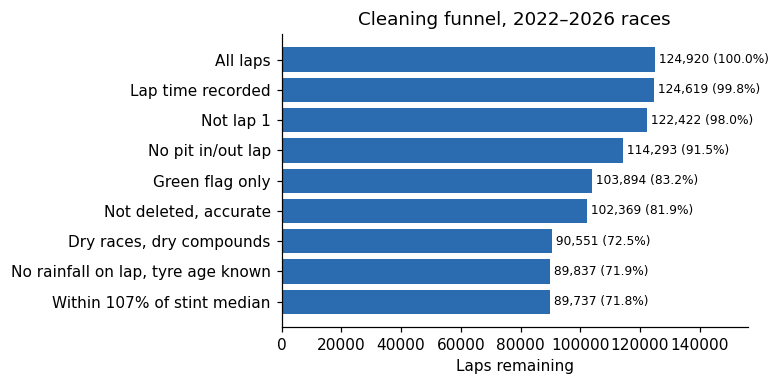

In [8]:
fig,ax=plt.subplots(figsize=(7,3.6))
ax.barh(funnel.step[::-1],funnel.laps[::-1],color='#2b6cb0')
for i,(n,p) in enumerate(zip(funnel.laps[::-1],funnel['% kept'][::-1])): ax.text(n,i,f' {n:,} ({p}%)',va='center',fontsize=8)
ax.set_xlabel('Laps remaining'); ax.set_title('Cleaning funnel, 2022–2026 races'); ax.set_xlim(0,funnel.laps.max()*1.25)
plt.tight_layout(); plt.savefig('figures/01_funnel.png',dpi=150); plt.show()

### 5. Target: lap-time delta to the race median
Raw lap times differ by circuit (a 70 s lap vs a 105 s lap), so we subtract each race's median clean lap time.

In [9]:
df = add_target(df)
df.groupby('season').lap_delta_s.describe().round(3)

,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
2022,15140.0,-0.034,1.286,-4.991,-0.879,0.0,0.784,6.508
2023,17788.0,0.054,1.227,-4.402,-0.752,0.0,0.805,24.170
2024,20156.0,0.008,1.291,-5.272,-0.894,0.0,0.865,6.333
2025,20131.0,0.028,1.226,-5.292,-0.805,0.0,0.852,8.985
2026,16522.0,0.164,1.607,-5.243,-0.940,0.0,1.139,10.768


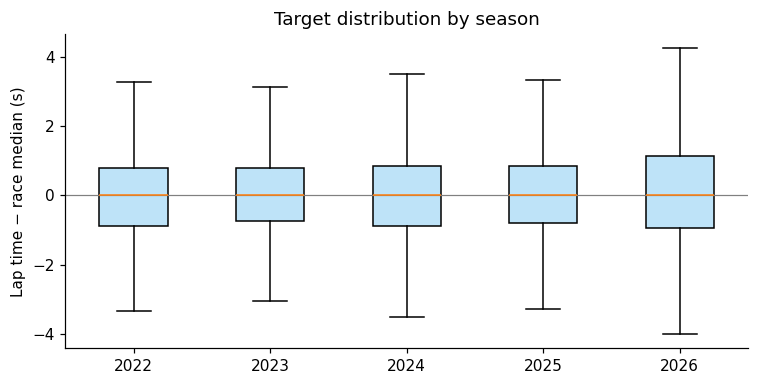

In [10]:
fig,ax=plt.subplots(figsize=(7,3.6))
data=[df.loc[df.season==y,'lap_delta_s'] for y in SEASONS]
ax.boxplot(data,tick_labels=SEASONS,showfliers=False,patch_artist=True,boxprops=dict(facecolor='#bee3f8'))
ax.axhline(0,color='grey',lw=.8); ax.set_ylabel('Lap time − race median (s)'); ax.set_title('Target distribution by season')
plt.tight_layout(); plt.savefig('figures/02_target_by_season.png',dpi=150); plt.show()

### 6. Feature encoding
`f1lap.features.add_features` maps team lineages and circuits (handling the 2026 relocations) and builds the fuel proxy; `encode_features` one-hot encodes compound and team lineage.

In [11]:
df = add_features(df)
print('Teams in 2026 not seen in 2022–2025:',sorted(df.loc[df.unseen_team,'team'].unique()))
train_drivers=set(df.loc[df.season<2026,'driver'])
print('2026 drivers with no 2022–2025 race laps:',sorted(set(df.loc[df.season==2026,'driver'])-train_drivers))
print('2026 circuits not raced dry in 2022–2025:',sorted(set(df.loc[df.season==2026,'circuit'])-set(df.loc[df.season<2026,'circuit'])))
features = encode_features(df)
print('Feature matrix:',features.shape, '| missing values:',int(features.isna().sum().sum()))

Teams in 2026 not seen in 2022–2025: ['Cadillac']
2026 drivers with no 2022–2025 race laps: ['HIR', 'LIN']
2026 circuits not raced dry in 2022–2025: ['Madrid']
Feature matrix: (89737, 20) | missing values: 0


### 7. First look at the regime shift

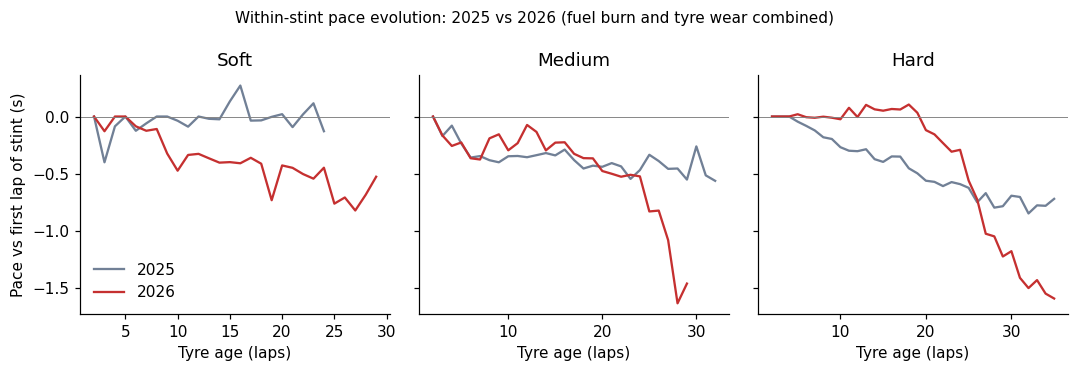

In [12]:
fig,axs=plt.subplots(1,3,figsize=(10,3.4),sharey=True)
colors={2025:'#718096',2026:'#c53030'}
for ax,cmp in zip(axs,['SOFT','MEDIUM','HARD']):
    for y in [2025,2026]:
        s=df[(df.season==y)&(df.compound==cmp)&(df.tyre_age<=35)]
        # within-stint pace change: delta relative to the stint's first clean lap
        s=s.assign(rel=s.lap_delta_s-s.groupby(['event','driver','stint']).lap_delta_s.transform('first'))
        g=s.groupby('tyre_age').rel.median(); n=s.groupby('tyre_age').size(); g=g[n>=50]
        ax.plot(g.index,g.values,color=colors[y],label=str(y))
    ax.set_title(cmp.title()); ax.set_xlabel('Tyre age (laps)'); ax.axhline(0,color='grey',lw=.6)
axs[0].set_ylabel('Pace vs first lap of stint (s)'); axs[0].legend(frameon=False)
fig.suptitle('Within-stint pace evolution: 2025 vs 2026 (fuel burn and tyre wear combined)',fontsize=10)
plt.tight_layout(); plt.savefig('figures/03_stint_pace_2025_vs_2026.png',dpi=150); plt.show()

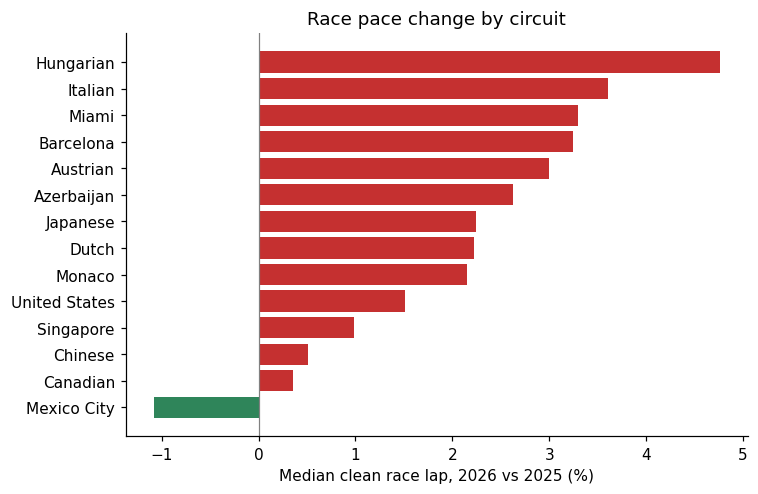

14 circuits raced dry in both years; median change 2.23%


In [13]:
med=df.groupby(['season','circuit']).race_median_s.first().unstack(0)
common=med[[2025,2026]].dropna(); common['change_s']=common[2026]-common[2025]
common['change_%']=(common.change_s/common[2025]*100).round(2)
common=common.sort_values('change_%')
fig,ax=plt.subplots(figsize=(7,4.6))
ax.barh(common.index,common['change_%'],color=np.where(common['change_%']>0,'#c53030','#2f855a'))
ax.axvline(0,color='grey',lw=.8); ax.set_xlabel('Median clean race lap, 2026 vs 2025 (%)'); ax.set_title('Race pace change by circuit')
plt.tight_layout(); plt.savefig('figures/04_pace_change_by_circuit.png',dpi=150); plt.show()
print(f'{len(common)} circuits raced dry in both years; median change {common["change_%"].median():.2f}%')

### 8. Save the clean, feature-ready table
Notebook 02 loads this file directly.

In [14]:
df.to_csv('data/clean_laps.csv.gz',index=False); print('Saved',df.shape)

Saved (89737, 24)
